# Stage 7 – Adversarial Attack Generation (FGSM, PGD and Carlini–Wagner)

**Research project:** Unsupervised graph-based adversarial attack detection and severity estimation in Alzheimer’s MRI classification.

This notebook generates adversarial examples using the trained Stage 4 CNN classifier. It uses the exact Stage 3 image splits and Stage 4 trained checkpoint.

## Important methodological points
- Attacks are generated against the trained CNN classifier, not against the DGI loss.
- The true class labels are used only to calculate the attack loss; they are not used to train the DGI model.
- We generate attacks separately for train, validation and test splits so later stages can use training examples for detector development and keep test examples for final evaluation.
- The CNN classifier is held fixed during attack generation.
- Images are grayscale, 128 × 128, and represented in [0, 1].
- FGSM and PGD use an L-infinity perturbation budget. Carlini–Wagner uses an L2 objective.
- We will save both adversarial images and perturbation measurements.

**Do not interpret successful attack generation as evidence that the detector works.** Detection and severity estimation will be evaluated in later stages.

## Attack parameters (initial reproducible settings)
These are explicit experimental settings for this implementation. If the manuscript specifies different values, use the manuscript values instead and record the final settings consistently.

| Attack | Initial parameters |
|---|---|
| FGSM | epsilon = 0.03 |
| PGD | epsilon = 0.03, alpha = 0.0075, 10 steps, random start |
| CW-L2 | confidence = 0, learning rate = 0.01, 100 iterations, 3 binary-search steps |

The CW implementation below is a practical untargeted L2 Carlini–Wagner-style optimization. Its exact objective and settings must be reported accurately; do not describe it as a library implementation with different defaults.

## Step 1 – Set up the environment

In [1]:
import os, json, zipfile, random, warnings, shutil, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cpu":
    print("NOTE: CW attacks can be slow on CPU. A Colab GPU runtime is strongly recommended.")

PyTorch: 2.11.0+cu130
Device: cuda


## Step 2 – Upload the Stage 3 and Stage 4 ZIP outputs

Upload:
- `Stage3_Preprocessing_Outputs.zip` (or the exact ZIP downloaded at the end of Stage 3)
- `Stage4_CNN_Outputs.zip`

The Stage 3 package provides the actual images and split assignments. The Stage 4 package provides the trained CNN checkpoint and split-index information.

In [2]:
from google.colab import files
uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving Stage3_Preprocessing_Outputs.zip to Stage3_Preprocessing_Outputs.zip
Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs.zip
Uploaded files: ['Stage3_Preprocessing_Outputs.zip', 'Stage4_CNN_Outputs.zip']


## Step 3 – Extract and inspect the ZIP contents

This step lists the contents. If the automatic file identification in the next steps cannot identify a particular array, stop and share this listing rather than guessing.

In [3]:
WORK = Path("/content/stage7_work")
S3 = WORK / "stage3"
S4 = WORK / "stage4"
S3.mkdir(parents=True, exist_ok=True); S4.mkdir(parents=True, exist_ok=True)

def safe_extract(zip_path, out_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise ValueError("Unsafe path detected in ZIP.")
        zf.extractall(out_dir)

names = list(uploaded.keys())
z3 = next((n for n in names if "stage3" in n.lower()), None)
z4 = next((n for n in names if "stage4" in n.lower()), None)
if z3 is None or z4 is None:
    raise FileNotFoundError("Please upload both the Stage 3 and Stage 4 output ZIP files.")
safe_extract(z3, S3); safe_extract(z4, S4)

print("STAGE 3 FILES")
for p in S3.rglob("*"):
    if p.is_file(): print(p.relative_to(S3), p.stat().st_size, "bytes")
print("\nSTAGE 4 FILES")
for p in S4.rglob("*"):
    if p.is_file(): print(p.relative_to(S4), p.stat().st_size, "bytes")

STAGE 3 FILES
split_manifest.csv 771838 bytes
preprocessing_config.json 781 bytes
alzheimer_images_uint8.npz 59977882 bytes
class_distribution_by_split.csv 138 bytes

STAGE 4 FILES
cnn_test_class_metrics.csv 265 bytes
cnn_embedding_manifest.csv 802746 bytes
stage4_config_and_metrics.json 997 bytes
cnn_training_history.csv 3703 bytes
best_alzheimer_cnn.pth 5071269 bytes
cnn_test_confusion_matrix.csv 171 bytes
cnn_embeddings_128d.npz 1087733 bytes


## Step 4 – Load the Stage 3 image arrays and labels

The Stage 3 ZIP layout can differ depending on the notebook version. This cell searches NPZ files and displays their keys and array shapes. It automatically selects arrays only when the matching image, label and index arrays are unambiguous.

In [4]:
npz3 = list(S3.rglob("*.npz"))
if not npz3:
    raise FileNotFoundError("No .npz data file found in Stage 3 ZIP.")
npz_info = []
for p in npz3:
    try:
        with np.load(p, allow_pickle=False) as z:
            npz_info.append((p, {k: (z[k].shape, str(z[k].dtype)) for k in z.files}))
    except Exception as e:
        print("Could not inspect", p.name, e)
for p, info in npz_info:
    print("\n", p.relative_to(S3))
    for k, v in info.items(): print(" ", k, v)


 alzheimer_images_uint8.npz
  X ((6400, 128, 128), 'uint8')
  y ((6400,), 'int64')
  class_names ((4,), '<U18')


### Identify the full image array and labels

Expected image array shape is `(6400, 128, 128)` or `(6400, 1, 128, 128)`. The label array must contain 6,400 entries. If there are multiple candidates, this cell deliberately stops and asks for review.

In [5]:
image_candidates = []
label_candidates = []
for p, info in npz_info:
    with np.load(p, allow_pickle=False) as z:
        for k in z.files:
            arr = z[k]
            if arr.ndim in (3,4) and arr.shape[0] == 6400 and (arr.shape[-2:] == (128,128)):
                image_candidates.append((p,k,arr.shape))
            if arr.ndim == 1 and arr.shape[0] == 6400:
                label_candidates.append((p,k,arr.shape,arr.dtype))

print("Image candidates:", image_candidates)
print("Label candidates:", label_candidates)
if len(image_candidates) != 1:
    raise RuntimeError("Image array is not uniquely identified. Review the printed candidates and share them.")
if len(label_candidates) != 1:
    raise RuntimeError("Label array is not uniquely identified. Review the printed candidates and share them.")

img_file, img_key, img_shape = image_candidates[0]
lab_file, lab_key, _, _ = label_candidates[0]
with np.load(img_file, allow_pickle=False) as z: images = z[img_key]
with np.load(lab_file, allow_pickle=False) as z: labels_raw = z[lab_key]

images = np.asarray(images)
if images.ndim == 3: images = images[:, None, :, :]
elif images.ndim == 4 and images.shape[1] != 1:
    raise ValueError(f"Expected grayscale channel dimension 1, got {images.shape}")
labels_raw = np.asarray(labels_raw)
print("Images:", images.shape, images.dtype, "range:", images.min(), images.max())
print("Labels:", labels_raw.shape, labels_raw.dtype, "unique:", np.unique(labels_raw, return_counts=True))

Image candidates: [(PosixPath('/content/stage7_work/stage3/alzheimer_images_uint8.npz'), 'X', (6400, 128, 128))]
Label candidates: [(PosixPath('/content/stage7_work/stage3/alzheimer_images_uint8.npz'), 'y', (6400,), dtype('int64'))]
Images: (6400, 1, 128, 128) uint8 range: 0 255
Labels: (6400,) int64 unique: (array([0, 1, 2, 3]), array([ 896,   64, 3200, 2240]))


## Step 5 – Recover the exact split indices and class mapping

We use the split indices saved by Stage 4 so that image, label and graph-node ordering remain consistent. We do not create a new split here.

In [6]:
npz4 = list(S4.rglob("*.npz"))
arr4 = {}
for p in npz4:
    try:
        with np.load(p, allow_pickle=False) as z:
            for k in z.files:
                if k not in arr4: arr4[k] = z[k]
    except Exception:
        pass
print("Stage 4 NPZ keys:", list(arr4.keys()))

def key_for(split, contains):
    matches = [k for k in arr4 if split in k.lower() and any(t in k.lower() for t in contains)]
    return matches[0] if len(matches)==1 else None

ki_tr = key_for("train", ["indice"])
ki_va = key_for("val", ["indice"]) or key_for("valid", ["indice"])
ki_te = key_for("test", ["indice"])
if not all([ki_tr,ki_va,ki_te]):
    raise KeyError("Could not uniquely identify Stage 4 split-index arrays. Share the key listing.")
train_idx = np.asarray(arr4[ki_tr], dtype=int)
val_idx = np.asarray(arr4[ki_va], dtype=int)
test_idx = np.asarray(arr4[ki_te], dtype=int)
assert len(np.unique(np.concatenate([train_idx,val_idx,test_idx]))) == 6400
assert set(np.concatenate([train_idx,val_idx,test_idx]).tolist()) == set(range(6400))

# Determine class-name mapping from a Stage 3/4 JSON config if available.
json_files = list(S3.rglob("*.json")) + list(S4.rglob("*.json"))
for p in json_files:
    try:
        obj = json.load(open(p))
        print("\nJSON:", p.name, json.dumps(obj, indent=2)[:2500])
    except Exception:
        pass

Stage 4 NPZ keys: ['train_embeddings', 'train_labels', 'train_predictions', 'train_indices', 'validation_embeddings', 'validation_labels', 'validation_predictions', 'validation_indices', 'test_embeddings', 'test_labels', 'test_predictions', 'test_indices', 'class_names']

JSON: preprocessing_config.json {
  "random_seed": 42,
  "image_dimensions": [
    128,
    128
  ],
  "image_mode": "grayscale",
  "stored_image_dtype": "uint8",
  "model_input_scaling": "float32 / 255.0, range [0,1]",
  "split_proportions": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  },
  "split_method": "two-step stratified train_test_split",
  "split_unit": "image-level",
  "patient_identifiers_available": false,
  "class_mapping": {
    "Mild Demented": 0,
    "Moderate Demented": 1,
    "Non-Demented": 2,
    "Very Mild Demented": 3
  },
  "total_images": 6400,
  "split_counts": {
    "train": 4480,
    "test": 960,
    "validation": 960
  },
  "class_counts": {
    "Non-Demented": 3200,
    "

### Important: confirm label encoding before attack generation

The CNN outputs four class logits. The label array must therefore contain integer class IDs 0–3 in exactly the same order used to train Stage 4. If Stage 3 stored string labels, or if the mapping is not available in the saved configuration, stop and share the printed unique labels/configuration. Do not invent a class order.

In [7]:
unique_labels = np.unique(labels_raw)
print("Unique labels:", unique_labels)
if not np.issubdtype(labels_raw.dtype, np.integer):
    raise TypeError("Labels are not integer class IDs. We need to recover the exact Stage 4 class-to-index mapping before proceeding.")
if not set(unique_labels.tolist()).issubset({0,1,2,3}):
    raise ValueError("Expected integer class IDs 0,1,2,3 for the four CNN output classes.")
labels = labels_raw.astype(np.int64)
print("Split counts:", len(train_idx), len(val_idx), len(test_idx))

Unique labels: [0 1 2 3]
Split counts: 4480 960 960


## Step 6 – Rebuild the Stage 4 CNN architecture and load its checkpoint

The architecture follows the Stage 4 implementation: four convolutional blocks (32, 64, 128, 256 channels), 2×2 max pooling, adaptive average pooling, a 128-dimensional feature layer, dropout and a four-class output layer.

In [9]:
class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.flatten = nn.Flatten()
        self.embedding = nn.Linear(256, 128)
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x, return_embedding=False):
        z = self.features(x)
        z = self.flatten(z)
        z = self.relu(self.embedding(z))
        if return_embedding: return z
        return self.classifier(self.dropout(z))

model = AlzheimerCNN(num_classes=4).to(DEVICE)
checkpoint_files = [p for p in S4.rglob("*") if p.suffix.lower() in [".pt",".pth"]]
print("Checkpoint candidates:", [str(p.relative_to(S4)) for p in checkpoint_files])
if len(checkpoint_files) != 1:
    raise RuntimeError("Expected exactly one Stage 4 model checkpoint. Review the printed candidates.")
checkpoint = torch.load(checkpoint_files[0], map_location=DEVICE, weights_only=False)
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state = checkpoint["state_dict"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state = checkpoint["model_state_dict"]
else:
    state = checkpoint
model.load_state_dict(state, strict=True)
model.eval()
print("Stage 4 CNN checkpoint loaded successfully.")

Checkpoint candidates: ['best_alzheimer_cnn.pth']
Stage 4 CNN checkpoint loaded successfully.


## Step 7 – Prepare tensors and verify clean classifier performance

The image values are converted to float32 and scaled to [0,1] only if the saved values are in the 0–255 range. If already normalized, they are retained.

In [10]:
X_img = images.astype(np.float32)
if X_img.max() > 1.0:
    X_img = X_img / 255.0
if X_img.min() < 0 or X_img.max() > 1.00001:
    raise ValueError("Images are not within [0,1] after preprocessing.")
X_tensor = torch.tensor(X_img, dtype=torch.float32)
y_tensor = torch.tensor(labels, dtype=torch.long)
print("Tensor shapes:", X_tensor.shape, y_tensor.shape)
print("Pixel range:", float(X_tensor.min()), float(X_tensor.max()))

@torch.no_grad()
def evaluate_indices(indices, batch_size=64):
    preds=[]; probs=[]
    for start in range(0,len(indices),batch_size):
        ids = indices[start:start+batch_size]
        xb = X_tensor[ids].to(DEVICE)
        logits = model(xb)
        preds.extend(logits.argmax(1).cpu().numpy())
        probs.extend(torch.softmax(logits,dim=1).cpu().numpy())
    preds=np.asarray(preds); probs=np.asarray(probs)
    yy=labels[indices]
    return {"accuracy":float((preds==yy).mean()),"predictions":preds,"probabilities":probs}

clean_metrics = {}
for split, idx in [("train",train_idx),("validation",val_idx),("test",test_idx)]:
    clean_metrics[split] = evaluate_indices(idx)
    print(split, "clean accuracy:", round(clean_metrics[split]["accuracy"],4))

Tensor shapes: torch.Size([6400, 1, 128, 128]) torch.Size([6400])
Pixel range: 0.0 1.0
train clean accuracy: 0.9605
validation clean accuracy: 0.8313
test clean accuracy: 0.826


## Step 8 – Implement FGSM and PGD attacks

Both attacks use the cross-entropy loss with the true class label and constrain the L-infinity perturbation. The image is clipped to [0,1] after each update.

In [11]:
def fgsm_attack(model, x, y, epsilon=0.03):
    x0 = x.detach()
    x_adv = x0.clone().requires_grad_(True)
    logits = model(x_adv)
    loss = F.cross_entropy(logits, y)
    grad = torch.autograd.grad(loss, x_adv)[0]
    adv = x0 + epsilon * grad.sign()
    return adv.clamp(0,1).detach()

def pgd_attack(model, x, y, epsilon=0.03, alpha=0.0075, steps=10, random_start=True):
    x0 = x.detach()
    if random_start:
        x_adv = x0 + torch.empty_like(x0).uniform_(-epsilon, epsilon)
        x_adv = x_adv.clamp(0,1)
    else:
        x_adv = x0.clone()
    for _ in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)
        logits = model(x_adv)
        loss = F.cross_entropy(logits, y)
        grad = torch.autograd.grad(loss, x_adv)[0]
        x_adv = x_adv.detach() + alpha * grad.sign()
        delta = torch.clamp(x_adv - x0, min=-epsilon, max=epsilon)
        x_adv = (x0 + delta).clamp(0,1)
    return x_adv.detach()

## Step 9 – Implement an untargeted Carlini–Wagner L2-style attack

This cell implements a tanh-space optimization with an L2 distance penalty and a classification-margin term. It uses a binary search over the penalty constant. CW is computationally expensive; the notebook runs it in batches and allows you to reduce the iteration count for a smoke test, but final reported experiments should use the declared settings consistently.

**CW settings:** confidence = 0, learning rate = 0.01, 100 optimization iterations, 3 binary-search steps. These are implementation settings, not claims about any unspecified manuscript parameters.

In [12]:
def cw_l2_attack(model, images, labels, confidence=0.0, learning_rate=0.01,
                 max_iterations=100, binary_search_steps=3, initial_const=0.01):
    device = images.device
    batch = images.shape[0]
    # Map [0,1] to tanh-space.
    x = images.clamp(1e-6,1-1e-6)
    w_orig = torch.atanh((x*2-1)*0.999999).detach()
    lower = torch.zeros(batch, device=device)
    upper = torch.full((batch,), 1e10, device=device)
    const = torch.full((batch,), initial_const, device=device)
    best_adv = x.clone()
    best_l2 = torch.full((batch,), float("inf"), device=device)

    for _ in range(binary_search_steps):
        w = w_orig.clone().detach().requires_grad_(True)
        optimizer_cw = torch.optim.Adam([w], lr=learning_rate)
        step_best_l2 = torch.full((batch,), float("inf"), device=device)
        step_best_adv = x.clone()

        for iteration in range(max_iterations):
            adv = (torch.tanh(w)+1)/2
            logits = model(adv)
            one_hot = F.one_hot(labels, num_classes=logits.shape[1]).bool()
            real = logits.gather(1, labels.view(-1,1)).squeeze(1)
            other = logits.masked_fill(one_hot, -1e9).max(dim=1).values
            # Untargeted CW margin: encourage a non-true class to exceed the true class.
            f = torch.clamp(real - other + confidence, min=0)
            l2 = ((adv-x).view(batch,-1)**2).sum(dim=1)
            loss = (l2 + const*f).sum()

            optimizer_cw.zero_grad()
            loss.backward()
            optimizer_cw.step()

            with torch.no_grad():
                pred = logits.argmax(dim=1)
                success = pred.ne(labels)
                improved = success & (l2 < step_best_l2)
                step_best_l2[improved] = l2[improved]
                step_best_adv[improved] = adv[improved]
                global_improved = success & (l2 < best_l2)
                best_l2[global_improved] = l2[global_improved]
                best_adv[global_improved] = adv[global_improved]

        success_step = step_best_l2 < float("inf")
        upper = torch.where(success_step, torch.minimum(upper, const), upper)
        lower = torch.where(success_step, lower, torch.maximum(lower, const))
        const = torch.where(upper < 1e9, (lower+upper)/2, const*10)

    return best_adv.detach()

## Step 10 – Generate adversarial examples for each split

The attack generation is performed in batches. We save the original image, adversarial image, true label and predictions for every sample. For CW, if an example cannot be successfully attacked within the configured optimization budget, the saved output remains the original image and the success flag is false.

In [13]:
ATTACK_CONFIG = {
    "FGSM": {"epsilon":0.03},
    "PGD": {"epsilon":0.03,"alpha":0.0075,"steps":10,"random_start":True},
    "CW_L2": {"confidence":0.0,"learning_rate":0.01,"max_iterations":100,"binary_search_steps":3,"initial_const":0.01}
}
BATCH_SIZE = 32

def generate_split_attack(split_name, indices, attack_name):
    adv_chunks=[]; pred_chunks=[]; clean_pred_chunks=[]
    for start in range(0,len(indices),BATCH_SIZE):
        ids = indices[start:start+BATCH_SIZE]
        xb = X_tensor[ids].to(DEVICE)
        yb = y_tensor[ids].to(DEVICE)
        if attack_name == "FGSM":
            adv = fgsm_attack(model, xb, yb, **ATTACK_CONFIG["FGSM"])
        elif attack_name == "PGD":
            adv = pgd_attack(model, xb, yb, **ATTACK_CONFIG["PGD"])
        elif attack_name == "CW_L2":
            adv = cw_l2_attack(model, xb, yb, **ATTACK_CONFIG["CW_L2"])
        else:
            raise ValueError(attack_name)
        with torch.no_grad():
            clean_pred = model(xb).argmax(1).cpu().numpy()
            adv_pred = model(adv).argmax(1).cpu().numpy()
        adv_chunks.append(adv.cpu().numpy())
        pred_chunks.append(adv_pred)
        clean_pred_chunks.append(clean_pred)
    adv_all = np.concatenate(adv_chunks, axis=0)
    adv_pred_all = np.concatenate(pred_chunks)
    clean_pred_all = np.concatenate(clean_pred_chunks)
    y_true = labels[indices]
    success = adv_pred_all != y_true
    delta = adv_all - X_tensor[indices].numpy()
    report = {
        "split":split_name, "attack":attack_name, "n":int(len(indices)),
        "attack_success_rate":float(success.mean()),
        "clean_accuracy":float((clean_pred_all==y_true).mean()),
        "adversarial_accuracy":float((adv_pred_all==y_true).mean()),
        "mean_abs_perturbation":float(np.mean(np.abs(delta))),
        "mean_l2_perturbation":float(np.mean(np.sqrt(np.sum(delta**2,axis=(1,2,3))))),
        "mean_linf_perturbation":float(np.max(np.abs(delta),axis=(1,2,3)).mean())
    }
    return adv_all, adv_pred_all, clean_pred_all, success, report

OUT = Path("/content/Stage7_Adversarial_Outputs")
OUT.mkdir(parents=True, exist_ok=True)
all_reports=[]
for split_name, indices in [("train",train_idx),("validation",val_idx),("test",test_idx)]:
    for attack_name in ["FGSM","PGD","CW_L2"]:
        start=time.time()
        print(f"Generating {attack_name} for {split_name} ({len(indices)} images)...")
        adv, adv_pred, clean_pred, success, report = generate_split_attack(split_name, indices, attack_name)
        np.savez_compressed(
            OUT / f"{split_name}_{attack_name}_adversarial.npz",
            indices=indices, original_images=X_tensor[indices].numpy(),
            adversarial_images=adv, labels=labels[indices],
            clean_predictions=clean_pred, adversarial_predictions=adv_pred,
            attack_success=success
        )
        all_reports.append(report)
        print("  success rate:", round(report["attack_success_rate"],4),
              "| elapsed min:", round((time.time()-start)/60,2))

Generating FGSM for train (4480 images)...
  success rate: 0.9996 | elapsed min: 0.49
Generating PGD for train (4480 images)...
  success rate: 0.9996 | elapsed min: 0.85
Generating CW_L2 for train (4480 images)...
  success rate: 1.0 | elapsed min: 16.72
Generating FGSM for validation (960 images)...
  success rate: 0.999 | elapsed min: 0.1
Generating PGD for validation (960 images)...
  success rate: 1.0 | elapsed min: 0.19
Generating CW_L2 for validation (960 images)...
  success rate: 1.0 | elapsed min: 3.57
Generating FGSM for test (960 images)...
  success rate: 1.0 | elapsed min: 0.11
Generating PGD for test (960 images)...
  success rate: 1.0 | elapsed min: 0.19
Generating CW_L2 for test (960 images)...
  success rate: 1.0 | elapsed min: 3.57


## Step 11 – Review attack metrics

Attack success rate is calculated over all images in the split, including images the clean classifier already misclassified. We also report clean accuracy and adversarial accuracy separately so the denominator is transparent. For a supplementary attack-success rate conditioned on initially correctly classified samples, we can calculate it in the next stage from the saved predictions.

In [14]:
report_df = pd.DataFrame(all_reports)
report_df.to_csv(OUT / "stage7_attack_summary.csv", index=False)
display(report_df)

,split,attack,n,attack_success_rate,clean_accuracy,adversarial_accuracy,mean_abs_perturbation,mean_l2_perturbation,mean_linf_perturbation
0,train,FGSM,4480,0.999554,0.960491,0.000446,0.022976,3.350425,0.030000
1,train,PGD,4480,0.999554,0.960491,0.000446,0.020276,2.972386,0.030000
2,train,CW_L2,4480,1.000000,0.960491,0.000000,0.000412,0.142505,0.023490
3,validation,FGSM,960,0.998958,0.831250,0.001042,0.022967,3.349763,0.030000
4,validation,PGD,960,1.000000,0.831250,0.000000,0.020272,2.971820,0.030000
5,validation,CW_L2,960,1.000000,0.831250,0.000000,0.000343,0.118846,0.019682
6,test,FGSM,960,1.000000,0.826042,0.000000,0.022943,3.348025,0.030000
7,test,PGD,960,1.000000,0.826042,0.000000,0.020282,2.972639,0.030000
8,test,CW_L2,960,1.000000,0.826042,0.000000,0.000333,0.115651,0.019063


## Step 12 – Visualize examples from each attack

The first test-set example is shown for illustration. The difference image is magnified for visibility; its displayed contrast is not the true perturbation magnitude.

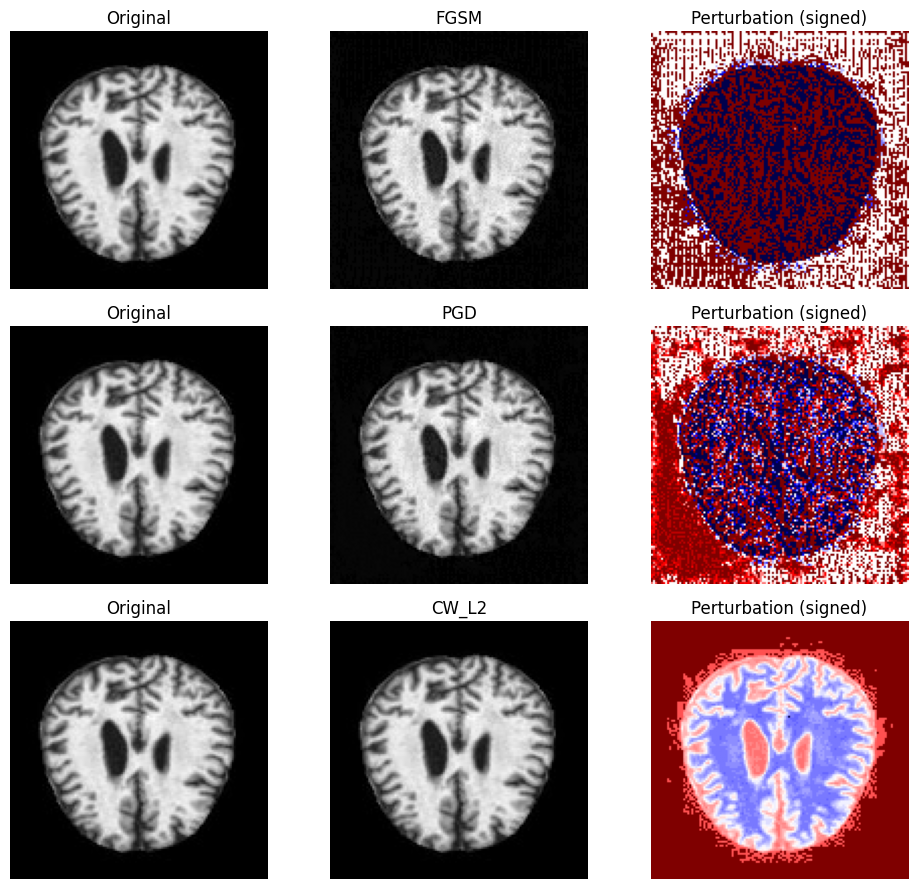

In [15]:
example_idx = 0
fig, axes = plt.subplots(3,3,figsize=(10,9))
for row, attack_name in enumerate(["FGSM","PGD","CW_L2"]):
    p = OUT / f"test_{attack_name}_adversarial.npz"
    with np.load(p, allow_pickle=False) as z:
        orig=z["original_images"][example_idx,0]
        adv=z["adversarial_images"][example_idx,0]
    diff=adv-orig
    axes[row,0].imshow(orig,cmap="gray",vmin=0,vmax=1); axes[row,0].set_title("Original")
    axes[row,1].imshow(adv,cmap="gray",vmin=0,vmax=1); axes[row,1].set_title(attack_name)
    axes[row,2].imshow(diff,cmap="seismic"); axes[row,2].set_title("Perturbation (signed)")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout(); plt.show()

## Step 13 – Save configuration and download the ZIP report

In [16]:
config = {
    "stage":7,
    "attacks":ATTACK_CONFIG,
    "image_shape":[1,128,128],
    "image_range":[0.0,1.0],
    "classifier":"Stage 4 four-block CNN with 128-D embedding and four output classes",
    "attack_target":"fixed Stage 4 CNN classifier",
    "splits":"Stage 3/4 saved image-level train/validation/test indices",
    "label_usage":"true labels used to compute attack loss; not used in DGI training",
    "attack_success_definition":"adversarial prediction differs from true label",
    "cw_description":"untargeted tanh-space L2 optimization with binary-search penalty",
    "seed":SEED,
    "device":str(DEVICE),
    "batch_size":BATCH_SIZE
}
with open(OUT/"stage7_attack_config.json","w") as f: json.dump(config,f,indent=2)

zip_path="/content/Stage7_Adversarial_Outputs.zip"
with zipfile.ZipFile(zip_path,"w",compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file(): zf.write(p,arcname=p.name)
print("Created:",zip_path)
files.download(zip_path)

Created: /content/Stage7_Adversarial_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 14 – What to send back

Upload `Stage7_Adversarial_Outputs.zip` here. I will check:
- all three attacks were generated for all splits;
- saved sample counts and split indices are correct;
- attack success rates and adversarial accuracies;
- perturbation magnitudes and FGSM/PGD L-infinity bounds;
- CW optimization outcomes;
- image examples and output completeness.

Also upload this notebook to your private GitHub repository as `Stage7_Adversarial_Attack_Generation.ipynb`.

**Do not proceed to Stage 8 until we have checked the outputs.**